# Model Comparison Visualization

This notebook visualizes the existing ResNet-18 and EfficientNet-B0 comparison results from `results/model_comparison.csv`. It does not train or evaluate models.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / 'results'
COMPARISON_PATH = RESULTS_DIR / 'model_comparison.csv'
assert COMPARISON_PATH.exists(), f'Missing comparison results: {COMPARISON_PATH}'


In [ ]:
comparison = pd.read_csv(COMPARISON_PATH)
metric_order = ['Test Accuracy', 'Precision', 'Recall', 'F1-score', 'Top-5 Accuracy']
model_colors = {'ResNet-18': '#176b87', 'EfficientNet-B0': '#e07a5f'}

required_columns = {'Metric', 'ResNet-18', 'EfficientNet-B0', 'ResNet-18 Total Parameters', 'EfficientNet-B0 Total Parameters'}
assert required_columns.issubset(comparison.columns)
metrics = comparison.set_index('Metric').loc[metric_order, ['ResNet-18', 'EfficientNet-B0']]
metrics


,ResNet-18,EfficientNet-B0,ResNet-18 Total Parameters,EfficientNet-B0 Total Parameters
Metric,,,,
Test Accuracy,0.686000,0.742000,11227812,4135648
Precision,0.725493,0.779000,11227812,4135648
Recall,0.686000,0.742000,11227812,4135648
F1-score,0.679440,0.737577,11227812,4135648
Top-5 Accuracy,0.904000,0.928000,11227812,4135648


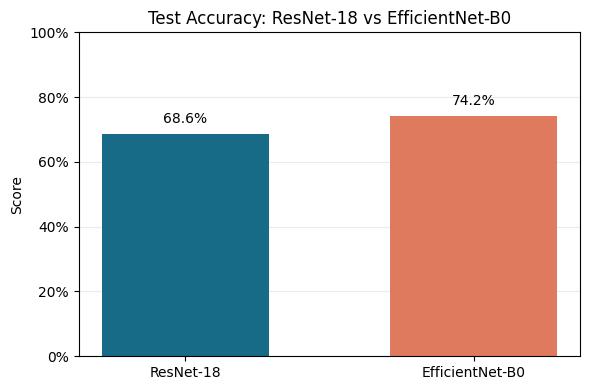

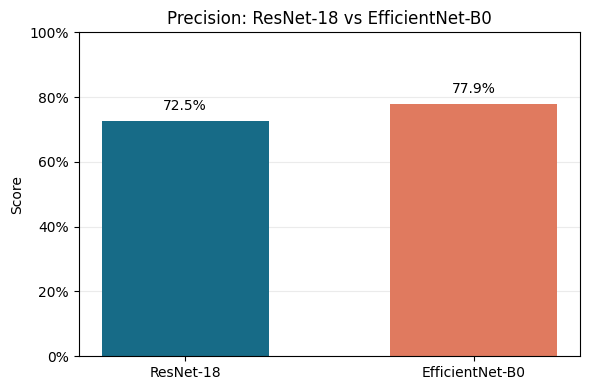

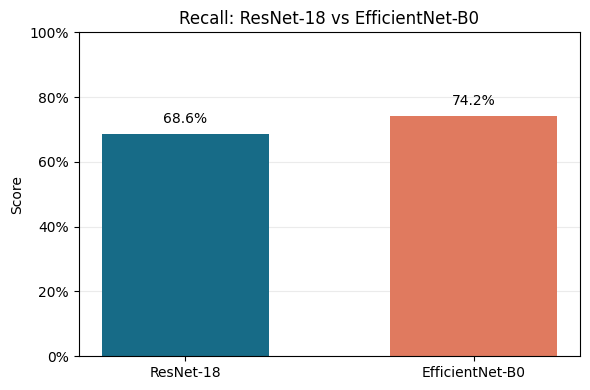

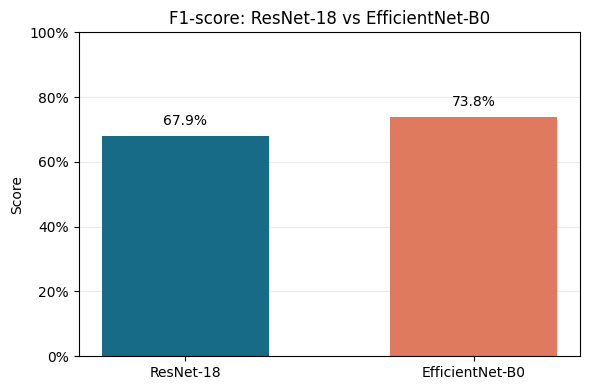

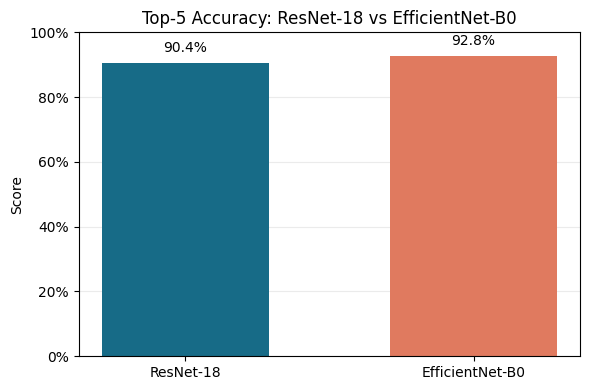

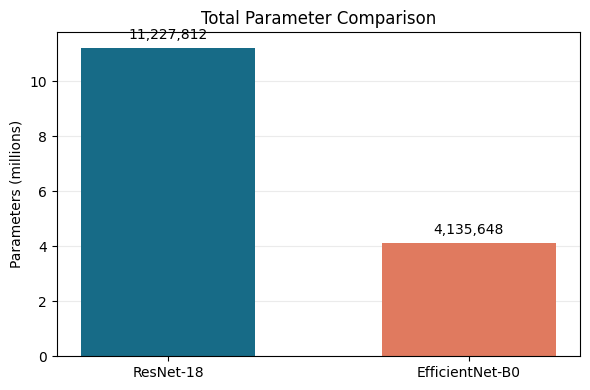

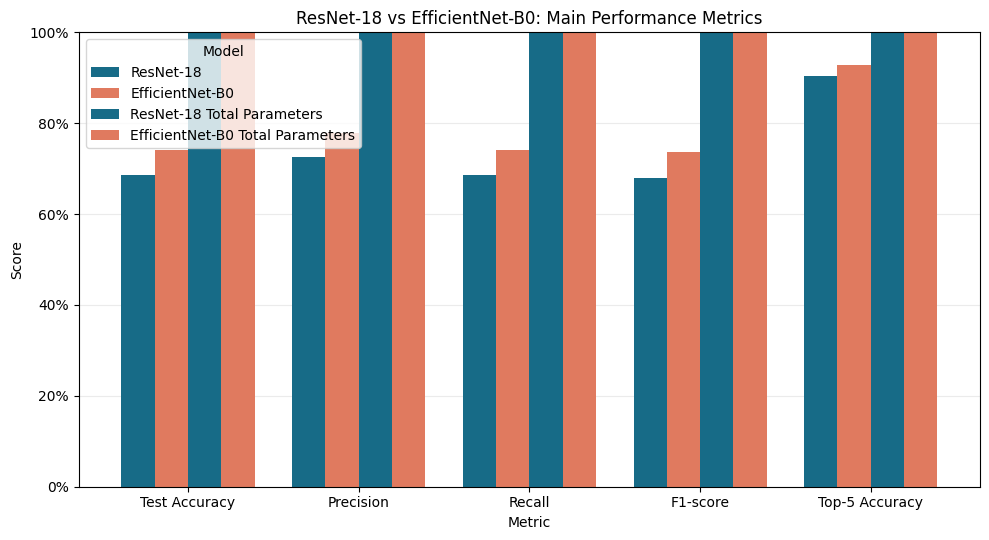

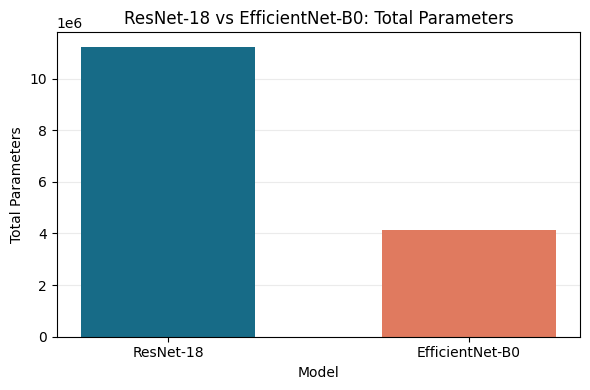

In [3]:
for metric in metric_order:
    values = metrics.loc[metric, ['ResNet-18', 'EfficientNet-B0']]
    figure, axis = plt.subplots(figsize=(6, 4))
    bars = axis.bar(values.index, values.values, color=[model_colors[model] for model in values.index], width=0.58)
    axis.set_title(f'{metric}: ResNet-18 vs EfficientNet-B0')
    axis.set_ylabel('Score')
    axis.set_ylim(0, 1)
    axis.yaxis.set_major_formatter(PercentFormatter(1))
    axis.grid(axis='y', alpha=0.25)
    axis.set_axisbelow(True)
    for bar, value in zip(bars, values.values):
        axis.text(bar.get_x() + bar.get_width() / 2, value + 0.025, f'{value:.1%}', ha='center', va='bottom')
    figure.tight_layout()
    plt.show()

parameter_values = pd.Series({
    'ResNet-18': comparison['ResNet-18 Total Parameters'].iloc[0],
    'EfficientNet-B0': comparison['EfficientNet-B0 Total Parameters'].iloc[0],
})
figure, axis = plt.subplots(figsize=(6, 4))
bars = axis.bar(parameter_values.index, parameter_values.values / 1_000_000, color=[model_colors[model] for model in parameter_values.index], width=0.58)
axis.set_title('Total Parameter Comparison')
axis.set_ylabel('Parameters (millions)')
axis.grid(axis='y', alpha=0.25)
axis.set_axisbelow(True)
for bar, value in zip(bars, parameter_values.values):
    axis.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2, f'{value:,.0f}', ha='center', va='bottom')
figure.tight_layout()
plt.show()

figure, axis = plt.subplots(figsize=(10, 5.5))
metrics.plot(kind='bar', ax=axis, color=[model_colors['ResNet-18'], model_colors['EfficientNet-B0']], width=0.78)
axis.set_title('ResNet-18 vs EfficientNet-B0: Main Performance Metrics')
axis.set_xlabel('Metric')
axis.set_ylabel('Score')
axis.set_ylim(0, 1)
axis.yaxis.set_major_formatter(PercentFormatter(1))
axis.legend(title='Model')
axis.grid(axis='y', alpha=0.25)
axis.set_axisbelow(True)
axis.tick_params(axis='x', rotation=0)
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'model_comparison_summary.png', dpi=180, bbox_inches='tight')
plt.show()

parameter_figure, parameter_axis = plt.subplots(figsize=(6, 4))
parameter_axis.bar(parameter_values.index, parameter_values.values, color=[model_colors[model] for model in parameter_values.index], width=0.58)
parameter_axis.set_title('ResNet-18 vs EfficientNet-B0: Total Parameters')
parameter_axis.set_xlabel('Model')
parameter_axis.set_ylabel('Total Parameters')
parameter_axis.grid(axis='y', alpha=0.25)
parameter_axis.set_axisbelow(True)
parameter_axis.ticklabel_format(axis='y', style='scientific', scilimits=(6, 6))
parameter_figure.tight_layout()
parameter_figure.savefig(RESULTS_DIR / 'model_parameter_comparison.png', dpi=180, bbox_inches='tight')
plt.show()


## Conclusion

Based on the existing comparison results, EfficientNet-B0 has the higher Test Accuracy, Precision, Recall, F1-score, and Top-5 Accuracy. It also uses fewer total parameters than ResNet-18. These visualizations summarize this experiment only and do not establish that either architecture is universally better.
